## Week 1: Linear Regression 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

### Dataframe 1

In [2]:
df1_animation = pd.read_csv("data/Animation_Movies_clean.csv")

In [3]:
financial = df1_animation.dropna(
    subset=["budget", "revenue"]
).copy()

financial["log_budget"] = np.log10(financial["budget"])
financial["log_revenue"] = np.log10(financial["revenue"])

financial.shape

(647, 22)

In [ ]:
X = financial[["log_budget"]]
y = financial["log_revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [5]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.03]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['log_budget']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.02479
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [ ]:
y_pred = model.predict(X_test)

In [ ]:
r2 = r2_score(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

print("Intercept:", model.intercept_)
print("Budget coefficient:", model.coef_[0])
print("R²:", r2)
print("RMSE:", rmse)

Intercept: -0.024790031387146527
Budget coefficient: 1.0279883262693337
R²: 0.9241217124061688
RMSE: 0.625589931034663


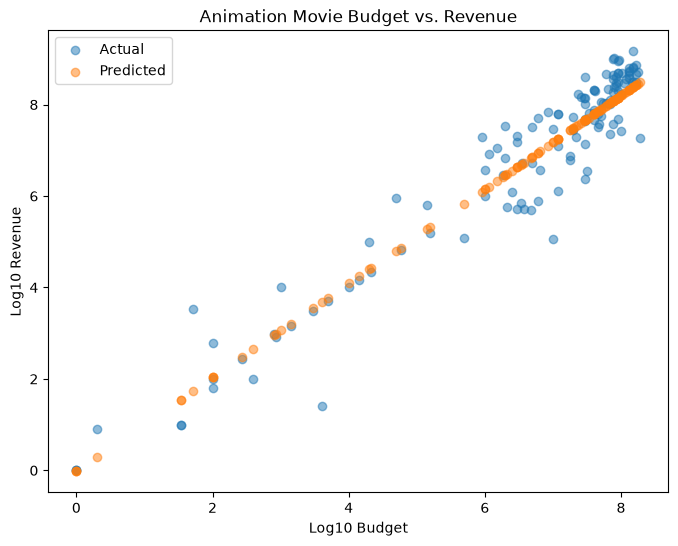

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_test["log_budget"],
    y_test,
    alpha=0.5,
    label="Actual"
)

plt.scatter(
    X_test["log_budget"],
    y_pred,
    alpha=0.5,
    label="Predicted"
)

plt.xlabel("Log10 Budget")
plt.ylabel("Log10 Revenue")
plt.title("Animation Movie Budget vs. Revenue")
plt.legend()

plt.show()

### Polynomial Regression: Dataframe 1

In [9]:
poly = PolynomialFeatures(degree=2, include_bias=False)

X_poly = poly.fit_transform(
    financial[["log_budget"]]
)

X_poly[:5]

array([[ 8.24303805, 67.94767627],
       [ 8.24303805, 67.94767627],
       [ 7.97312785, 63.57076777],
       [ 8.24303805, 67.94767627],
       [ 8.25527251, 68.14952413]])

In [10]:
y = financial["log_revenue"]

In [11]:
X_train_poly, X_test_poly, y_train, y_test = train_test_split(
    X_poly,
    y,
    test_size=0.2,
    random_state=42
)

In [12]:
poly_model = LinearRegression()

poly_model.fit(X_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0.83,0.02]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.3035
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[455.73, 10.06]"


In [13]:
y_pred_poly = poly_model.predict(X_test_poly)

In [14]:
poly_r2 = r2_score(y_test, y_pred_poly)

poly_rmse = mean_squared_error(
    y_test,
    y_pred_poly
) ** 0.5

print("Polynomial R²:", poly_r2)
print("Polynomial RMSE:", poly_rmse)

Polynomial R²: 0.9254388220942081
Polynomial RMSE: 0.6201366082284011


In [15]:
print("Intercept:", poly_model.intercept_)
print("Coefficients:", poly_model.coef_)

Intercept: 0.30350326081435774
Coefficients: [0.83323633 0.02032078]


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


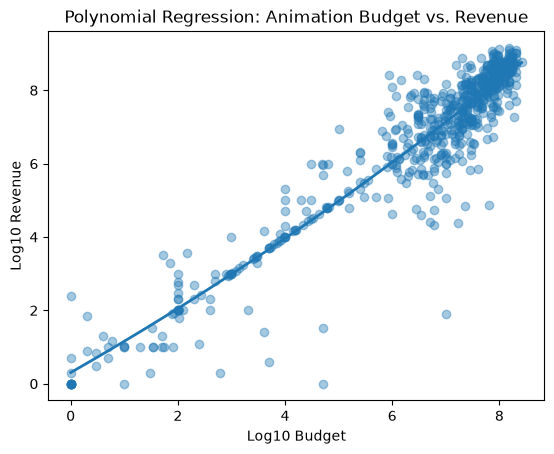

In [16]:
# Sort budget values so the curve is drawn in order
sort_index = np.argsort(financial["log_budget"].values)

X_sorted = financial[["log_budget"]].values[sort_index]

# Transform the sorted budget values
X_sorted_poly = poly.transform(X_sorted)

# Predict revenue
y_sorted_pred = poly_model.predict(X_sorted_poly)

# Plot
plt.scatter(
    financial["log_budget"],
    financial["log_revenue"],
    alpha=0.4
)

plt.plot(
    X_sorted,
    y_sorted_pred,
    linewidth=2
)

plt.xlabel("Log10 Budget")
plt.ylabel("Log10 Revenue")
plt.title("Polynomial Regression: Animation Budget vs. Revenue")

plt.show()

### Popularity/Revenue

In [18]:
pop_revenue = df1_animation[
    ["popularity", "revenue"]
].dropna().copy()

pop_revenue = pop_revenue[
    (pop_revenue["popularity"] > 0) &
    (pop_revenue["revenue"] > 0)
]

pop_revenue.shape

(1090, 2)

In [19]:
pop_revenue["log_popularity"] = np.log10(
    pop_revenue["popularity"]
)

pop_revenue["log_revenue"] = np.log10(
    pop_revenue["revenue"]
)

In [20]:
X = pop_revenue[["log_popularity"]]
y = pop_revenue["log_revenue"]

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [22]:
pop_model = LinearRegression()

pop_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2.12]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['log_popularity']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.512
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [23]:
y_pred = pop_model.predict(X_test)

In [24]:
pop_r2 = r2_score(y_test, y_pred)

pop_rmse = mean_squared_error(
    y_test,
    y_pred
) ** 0.5

print("Intercept:", pop_model.intercept_)
print("Popularity coefficient:", pop_model.coef_[0])
print("R²:", pop_r2)
print("RMSE:", pop_rmse)

Intercept: 4.512112287483743
Popularity coefficient: 2.118406041300778
R²: 0.5996843772372874
RMSE: 1.3162084807439423


### Interaction Terms

In [25]:
interaction_data = df1_animation.dropna(
    subset=["budget", "revenue", "popularity"]
).copy()

interaction_data = interaction_data[
    (interaction_data["budget"] > 0) &
    (interaction_data["revenue"] > 0) &
    (interaction_data["popularity"] > 0)
]

interaction_data["log_budget"] = np.log10(
    interaction_data["budget"]
)

interaction_data["log_revenue"] = np.log10(
    interaction_data["revenue"]
)

interaction_data["log_popularity"] = np.log10(
    interaction_data["popularity"]
)

interaction_data.shape

(637, 23)

In [26]:
interaction_data["budget_popularity"] = (
    interaction_data["log_budget"] *
    interaction_data["log_popularity"]
)

In [27]:
X = interaction_data[
    [
        "log_budget",
        "log_popularity",
        "budget_popularity"
    ]
]

y = interaction_data["log_revenue"]

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [29]:
interaction_model = LinearRegression()

interaction_model.fit(
    X_train,
    y_train
)

y_pred = interaction_model.predict(X_test)

In [30]:
interaction_r2 = r2_score(
    y_test,
    y_pred
)

interaction_rmse = mean_squared_error(
    y_test,
    y_pred
) ** 0.5

print("R²:", interaction_r2)
print("RMSE:", interaction_rmse)

R²: 0.9286498444881544
RMSE: 0.6447878633046159


In [31]:
print("Intercept:", interaction_model.intercept_)

for name, coef in zip(
    X.columns,
    interaction_model.coef_
):
    print(name, ":", coef)

Intercept: 0.7121081213974136
log_budget : 0.8136994088242115
log_popularity : 0.9631802669816187
budget_popularity : -0.03652058816723791


### Dataframe 2

In [32]:
df2_action = pd.read_csv("data/Action_Movies_clean.csv")

In [33]:
action_reg = df2_action.dropna(
    subset=["rating", "gross(in $)"]
).copy()

action_reg = action_reg[
    action_reg["gross(in $)"] > 0
]

action_reg["log_gross"] = np.log10(
    action_reg["gross(in $)"]
)

action_reg.shape

(2760, 15)

In [34]:
X = action_reg[["rating"]]

y = action_reg["log_gross"]

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [36]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

y_pred_linear = linear_model.predict(X_test)

In [37]:
linear_r2 = r2_score(
    y_test,
    y_pred_linear
)

linear_rmse = mean_squared_error(
    y_test,
    y_pred_linear
) ** 0.5

print("Linear R²:", linear_r2)
print("Linear RMSE:", linear_rmse)

Linear R²: 0.09141675563631524
Linear RMSE: 1.2440207319532801


### Polynomial Regression

In [39]:
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [40]:
poly_model = LinearRegression()

poly_model.fit(
    X_train_poly,
    y_train
)

y_pred_poly = poly_model.predict(
    X_test_poly
)

In [41]:
poly_r2 = r2_score(
    y_test,
    y_pred_poly
)

poly_rmse = mean_squared_error(
    y_test,
    y_pred_poly
) ** 0.5

print("Polynomial R²:", poly_r2)
print("Polynomial RMSE:", poly_rmse)

Polynomial R²: 0.09069386469175678
Polynomial RMSE: 1.2445155201436613


In [42]:
votes_reg = df2_action.dropna(
    subset=["votes", "gross(in $)"]
).copy()

votes_reg = votes_reg[
    (votes_reg["votes"] > 0) &
    (votes_reg["gross(in $)"] > 0)
]

votes_reg["log_votes"] = np.log10(
    votes_reg["votes"]
)

votes_reg["log_gross"] = np.log10(
    votes_reg["gross(in $)"]
)

votes_reg.shape

(2760, 16)

In [43]:
X = votes_reg[["log_votes"]]

y = votes_reg["log_gross"]

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [45]:
votes_linear_model = LinearRegression()

votes_linear_model.fit(
    X_train,
    y_train
)

y_pred_linear = votes_linear_model.predict(
    X_test
)

In [46]:
linear_r2 = r2_score(
    y_test,
    y_pred_linear
)

linear_rmse = mean_squared_error(
    y_test,
    y_pred_linear
) ** 0.5

print("Linear R²:", linear_r2)
print("Linear RMSE:", linear_rmse)

Linear R²: 0.510510561877212
Linear RMSE: 0.9130970064351125


In [47]:
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [48]:
votes_poly_model = LinearRegression()

votes_poly_model.fit(
    X_train_poly,
    y_train
)

y_pred_poly = votes_poly_model.predict(
    X_test_poly
)

In [49]:
poly_r2 = r2_score(
    y_test,
    y_pred_poly
)

poly_rmse = mean_squared_error(
    y_test,
    y_pred_poly
) ** 0.5

print("Polynomial R²:", poly_r2)
print("Polynomial RMSE:", poly_rmse)

Polynomial R²: 0.525008544742538
Polynomial RMSE: 0.8994730485044896
